# Fig. S3: thermodynamic bound on the response resolution for B-type perturbations

Random three-state networks; the response resolution normalized by its upper bound (SI Appendix, Sec. VI).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join('..', 'lib')))
OUT = os.path.abspath(os.path.join('..', 'figures'))
os.makedirs(OUT, exist_ok=True)

import numpy as np
np.random.seed(2026)

## Model and helper functions

In [2]:
from ftMarkov import *
import matplotlib.pyplot as plt
import numpy as np

def generate_matrix(E,B,F):
    size = np.shape(E)[0]
    # Compute rates
    W = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            if i != j:
                W[i,j] = np.exp(-(B[i,j] - E[j] - F[i,j]/2))
    W = W - np.diag(W.sum(axis=0))
    return W

def generate_random_network(size, scale=12.0,seed=None):
    if seed is not None:
        np.random.seed(seed)
    """Generate random network parameters and transition rates"""
    # Generate parameters
    E = (np.random.rand(size)-0.5)*scale
    B = (np.random.rand(size, size)-0.5)*scale
    B = (B + B.T) / 2  # symmetric
    F = (np.random.rand(size,size)-0.5)*scale
    F = (F - F.T) / 2  # antisymmetric
    W = generate_matrix(E,B,F)
    return W, E, B, F

def compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable, response_fn,return_linear_response=False):
    """Compute response for a single edge over different perturbation strengths, using a user-specified response function"""
    # = MarkovNet(W)
    markov = MarkovNet( generate_matrix(E, B, F))
    #markov_small = W_small)
    original_pss = markov.pss
    # if postive:
    #     observable = np.random.randn(len(W))#np.exp(-8*np.random.randn(len(W)))#np.random.randn(len(W))
    # else:
    #     observable = #(np.random.randn(len(W)) - 0.5)
    original_obs = np.sum(observable * original_pss)
    original_obs_sq = np.sum((observable**2) * original_pss)
    original_variance = original_obs_sq - original_obs**2
    # First compute linear response (eps->0 limit)
    eps_small = 1e-4
    E_small, B_small, F_small = E.copy(), B.copy(), F.copy()
    
    if perturb_type == 'B':
        B_small[m,n] += eps_small
        B_small[n,m] += eps_small
    elif perturb_type == 'F':
        F_small[m,n] += eps_small
        F_small[n,m] -= eps_small
    elif perturb_type == 'E':
        E_small[m] += eps_small
    elif perturb_type == 'A':
        # For A perturbation, we directly perturb the A matrix element
        # A[i,j] = B[i,j] - E[j] - F[i,j]/2
        # So perturbing A[m,n] by eps_small is equivalent to perturbing B[m,n] by eps_small
        B_small[m,n] += eps_small
        
    W_small = generate_matrix(E_small, B_small, F_small)
    markov_small = MarkovNet(W_small)
    new_obs_small = np.sum(observable * markov_small.pss)
    linear_response = (new_obs_small - original_obs) / eps_small
    
    responses = []
    for eps in eps_range:
        E_new, B_new, F_new = E.copy(), B.copy(), F.copy()
        if perturb_type == 'B':
            B_new[m,n] += eps
            B_new[n,m] += eps
        elif perturb_type == 'F':
            F_new[m,n] += eps
            F_new[n,m] -= eps
        elif perturb_type == 'E':
            E_new[m] += eps
        elif perturb_type == 'A':
            # For A perturbation, we directly perturb the A matrix element
            # A[i,j] = B[i,j] - E[j] - F[i,j]/2
            # So perturbing A[m,n] by eps is equivalent to perturbing B[m,n] by eps
            B_new[m,n] += eps
        
        W_new = generate_matrix(E_new, B_new, F_new)
        markov_new = MarkovNet(W_new)
        new_pss = markov_new.pss
        new_obs = np.sum(observable * new_pss)
        # Calculate variance in perturbed case
        new_obs_sq = np.sum((observable**2) * new_pss)
        new_variance = new_obs_sq - new_obs**2
        
        # compute the response with the user-supplied function
        response = response_fn(original_obs, new_obs, eps,linear_response, original_variance, new_variance)
        responses.append(response)
    if return_linear_response:
        return responses, linear_response
    else:
        return responses


def plot_results(all_responses, eps_range, perturb_type):
    """Create plot of responses vs perturbation strength"""
    # Define colors for different perturbation types
    colors = {'B': '#0072B2', 'F': '#1f77b4', 'E': '#D55E00', 'A': '#009E73'}
    # Plot response for each network
    for i, responses in enumerate(all_responses):
        plt.plot(eps_range, responses, '-',
                alpha=0.2, color=colors[perturb_type])
    
    #plt.xlabel(f'Perturbation Strength ($\Delta {perturb_type}$)')
    #plt.ylabel(r'Current Response / Linear Response, $\frac{\Delta J_{mn}}{e^{\Delta F_e}-1}\left(\partial_{F_e}J_{mn}\right)^{-1}$')
    plt.grid(True, which="both", ls="-", alpha=0.2)
    return plt.gcf()


## Plotting helper

In [3]:
def plot_results(all_responses, eps_range, perturb_type):
    """Create plot of responses vs perturbation strength"""
    # Define colors for different perturbation types
    colors = {'B': '#0072B2', 'F': '#1f77b4', 'E': '#D55E00', 'A': '#009E73'}
    
    # Plot response for each network
    for i, responses in enumerate(all_responses):
        plt.plot(eps_range, responses, '-',
                alpha=0.9, color=colors[perturb_type])
    
    #plt.xlabel(f'Perturbation Strength ($\Delta {perturb_type}$)')
    #plt.ylabel(r'Current Response / Linear Response, $\frac{\Delta J_{mn}}{e^{\Delta F_e}-1}\left(\partial_{F_e}J_{mn}\right)^{-1}$')
    plt.grid(True, which="both", ls="-", alpha=0.2)
    return plt.gcf()


## Fig. S3(a)

Computing responses for 500 networks...
Network 0/500
Network 10/500


Network 20/500
Network 30/500


Network 40/500
Network 50/500


Network 60/500
Network 70/500


Network 80/500
Network 90/500


...

Network 420/500
Network 430/500


Network 440/500
Network 450/500


Network 460/500
Network 470/500


Network 480/500
Network 490/500


Creating plot...


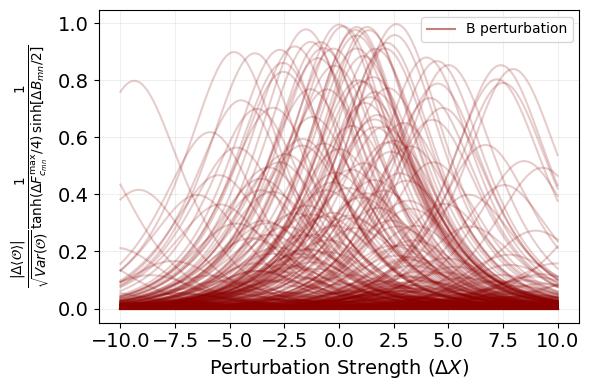

In [4]:

def response_fn(original_obs, new_obs, eps, linear_response, original_variance,new_variance):
    return np.abs(new_obs - original_obs) /np.sqrt(original_variance)
# Parameters
SIZE = 3
N_NETWORKS = 500  # Number of different networks to generate
eps_range = np.linspace(-10, 10, 500)

# List of perturbation types to try in random order
perturb_types = ['B']
np.random.shuffle(perturb_types)

# Dictionary to store responses for each type
all_responses_dict = {ptype: [] for ptype in perturb_types}

# Colors for each perturbation type
colors = {'B': '#8B0000', 'F': '#1f77b4', 'E': '#2ca02c', 'A': '#009E73'}

print(f"Computing responses for {N_NETWORKS} networks...")
Fc_list = []
max_response_ = []
for i in range(N_NETWORKS):
    if i % 10 == 0:
        print(f"Network {i}/{N_NETWORKS}")
        
    # Generate random network
    W, E, B, F = generate_random_network(SIZE,scale=20)
    Fc = np.abs(np.log(W[0,1]*W[1,2]*W[2,0]/(W[0,2]*W[1,0]*W[2,1])))
    Fc_list.append(Fc)
    # Choose random edge to perturb
    while True:
        m = np.random.randint(0, SIZE)
        n = np.random.randint(0, SIZE)
        if m != n and W[m,n] != 0 and W[n,m] != 0:
            break
            
    # Compute responses for each perturbation type
    for perturb_type in perturb_types:
        observable = (np.random.randn(len(W)) - 0.5)
        responses = compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable,response_fn)/np.tanh(Fc/4)
        all_responses_dict[perturb_type].append(responses)
    max_response_.append(np.max(responses/np.abs(np.sinh(eps_range/2))))
# Plot results for each perturbation type
print("Creating plot...")
plt.figure(figsize=(6, 4))
for perturb_type in perturb_types:
    for i, responses in enumerate(all_responses_dict[perturb_type]):
        plt.plot(eps_range, responses/np.abs(np.sinh(eps_range/2)), '-',
                alpha=0.2, color=colors[perturb_type])
        # plt.plot(eps_range, responses/np.abs(np.sinh(eps_range/2)), '-',
        #         alpha=0.2, color=colors[perturb_type])
        
    #plt.xlabel(f'Perturbation Strength ($\Delta {perturb_type}$)')
    #plt.ylabel(r'Current Response / Linear Response, $\frac{\Delta J_{mn}}{e^{\Delta F_e}-1}\left(\partial_{F_e}J_{mn}\right)^{-1}$')
    plt.grid(True, which="both", ls="-", alpha=0.2)
    #return plt.gcf()
    #plot_results(all_responses_dict[perturb_type], eps_range, perturb_type)

# Add legend
legend_elements = [plt.Line2D([0], [0], color=colors[pt], label=f'{pt} perturbation', alpha=0.5) 
                    for pt in perturb_types]
plt.legend(handles=legend_elements)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
#plt.legend(fontsize=14)
# Add bounds
#plt.plot(eps_range, np.ones(eps_range.shape)/2,'--', linewidth=3,color='#4B9FE1')  # brighter blue
#plt.plot(eps_range, np.sinh(eps_range/2),'--', linewidth=3,color='#FF6B6B')  # brighter red
plt.xlabel(r'Perturbation Strength ($\Delta X$)',fontsize=14)
#plt.ylabel(r'Response / Noise, $\frac{|\Delta \langle \mathcal{O}\rangle|}{e^{\Delta X/2}-e^{-\Delta X/2}}\frac{1}{\sqrt{Var(\mathcal{O})} }$')
plt.ylabel(r'$\frac{|\Delta \langle \mathcal{O}\rangle|}{\sqrt{Var(\mathcal{O})} }\frac{1}{\tanh(\Delta F_{c_{mn}}^{\rm max}/4)}\frac{1}{\sinh[\Delta B_{mn}/2]}$',fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'FigS3a_B_resolution_bound.svg'),bbox_inches='tight')
plt.show()


## Fig. S3(b)

Computing responses for 500 networks...
Network 0/500


Network 50/500


Network 100/500


Network 150/500


Network 200/500


...

Network 300/500


Network 350/500


Network 400/500


Network 450/500


Creating plot...


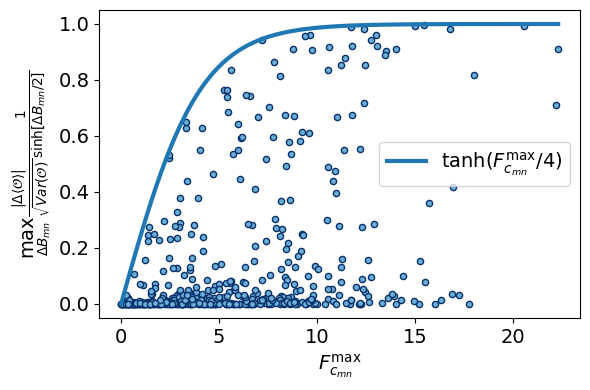

In [5]:

def response_fn(original_obs, new_obs, eps, linear_response, original_variance,new_variance):
    return np.abs(new_obs - original_obs) /np.sqrt(original_variance)
# Parameters
SIZE = 3
N_NETWORKS = 500  # Number of different networks to generate
eps_range = np.linspace(-10, 10, 500)

# List of perturbation types to try in random order
perturb_types = ['B']
np.random.shuffle(perturb_types)

# Dictionary to store responses for each type
all_responses_dict = {ptype: [] for ptype in perturb_types}

# Colors for each perturbation type
colors = {'B': '#8B0000', 'F': '#1f77b4', 'E': '#2ca02c', 'A': '#009E73'}

print(f"Computing responses for {N_NETWORKS} networks...")
Fc_list = []
max_response_ = []
for i in range(N_NETWORKS):
    if i % 50 == 0:
        print(f"Network {i}/{N_NETWORKS}")
        
    # Generate random network
    W, E, B, F = generate_random_network(SIZE,scale=20)
    Fc = np.abs(np.log(W[0,1]*W[1,2]*W[2,0]/(W[0,2]*W[1,0]*W[2,1])))
    Fc_list.append(Fc)
    # Choose random edge to perturb
    while True:
        m = np.random.randint(0, SIZE)
        n = np.random.randint(0, SIZE)
        if m != n and W[m,n] != 0 and W[n,m] != 0:
            break
            
    # Compute responses for each perturbation type
    for perturb_type in perturb_types:
        observable = (np.random.randn(len(W)) - 0.5)
        responses = compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable,response_fn)
        all_responses_dict[perturb_type].append(responses)
    max_response_.append(np.max(responses/np.abs(np.sinh(eps_range/2))))
# Plot results for each perturbation type
print("Creating plot...")
plt.figure(figsize=(6, 4))
Fc_list = np.array(Fc_list)
x_list = np.linspace(0,np.max(Fc_list),100)
plt.plot(x_list,np.tanh(x_list/4),linewidth=3.0,label=r'$\tanh(F_{c_{mn}}^{\max}/4)$')
plt.scatter(Fc_list ,max_response_,edgecolors='#08306b',c='#6baed6',alpha=1,s=20)



# Add legend

plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
#plt.legend(fontsize=14)
# Add bounds
#plt.plot(eps_range, np.ones(eps_range.shape)/2,'--', linewidth=3,color='#4B9FE1')  # brighter blue
#plt.plot(eps_range, np.sinh(eps_range/2),'--', linewidth=3,color='#FF6B6B')  # brighter red
plt.xlabel(r'$F_{c_{mn}}^{\rm max}$',fontsize=14)
#plt.ylabel(r'Response / Noise, $\frac{|\Delta \langle \mathcal{O}\rangle|}{e^{\Delta X/2}-e^{-\Delta X/2}}\frac{1}{\sqrt{Var(\mathcal{O})} }$')
plt.ylabel(r'$\max_{\Delta B_{mn}}\frac{|\Delta \langle \mathcal{O}\rangle|}{\sqrt{Var(\mathcal{O})} }\frac{1}{\sinh[\Delta B_{mn}/2]}$',fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'FigS3b_B_resolution_bound.svg'),bbox_inches='tight')
plt.show()
